# Emeritus College Membership Analytics — EDA & Modeling Walkthrough

This notebook is a readable, narrative walkthrough of the full pipeline implemented in `src/`.
It is meant as a portfolio artifact — the production code lives in `src/*.py` and is covered by
`tests/`; this notebook tells the story of *why* each step was taken and what it found.

**Data note:** all data used here is synthetically generated (see `data/raw/README.md`) and
contains no real member information.


In [1]:
import sys
sys.path.insert(0, "..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (9, 5)


## 1. Data cleaning & record linkage

We start from three independent spreadsheets with no shared reliable key.

In [2]:
from src.data_cleaning import build_clean_dataset

clean = build_clean_dataset()
print(f"Linked {len(clean)} records across 3 source files")
clean["source_status"].value_counts()


Linked 1194 records across 3 source files


source_status
active          523
special_case    440
deceased        231
Name: count, dtype: int64

In [3]:
clean[["member_id", "first_name", "last_name", "city", "state",
       "source_status", "has_current_ev_subscription"]].sample(10, random_state=1)


,member_id,first_name,last_name,city,state,source_status,has_current_ev_subscription
49,50,Andres,Banks,Gilbert,AZ,active,False
1140,1141,Corey,White,Tucson,AZ,deceased,False
306,307,Terri,Flores,Denver,CO,special_case,False
1016,1017,Jeremy,Stephenson,San Diego,CA,special_case,False
860,861,Shelly,Rhodes,Flagstaff,AZ,active,False
817,818,Karen,Peterson,Flagstaff,AZ,deceased,False
764,765,John,Newton,Flagstaff,AZ,active,False
904,905,Lindsey,Rodriguez,Sedona,AZ,special_case,False
661,662,Crystal,Mason,Peoria,AZ,special_case,False
599,600,Yolanda,Lawrence,Sedona,AZ,active,False


### Data quality issues found

- A handful of ASU IDs are the literal string `"Unknown"` and were linked purely on the fuzzy
  name+zip key instead.
- Some "Discipline"/"Joined EC" cells actually contain an administrative note
  (e.g. *"Has requested removal from all email lists"*) rather than real data — these were
  detected and split out into a proper `opted_out_of_email` flag.


In [4]:
resolved_id_pct = clean["asu_id"].notna().mean()
opted_out = clean["opted_out_of_email"].sum() if "opted_out_of_email" in clean else 0
print(f"Resolved numeric ASU IDs: {resolved_id_pct:.1%}")
print(f"Members flagged as opted out of email (data-quality repair): {opted_out}")


Resolved numeric ASU IDs: 99.2%
Members flagged as opted out of email (data-quality repair): 106


## 2. Feature engineering

In [5]:
from src.features import engineer_features

features = engineer_features(clean)
print(f"Active members in scope for the renewal model: {len(features)}")
print(f"Renewal rate: {features['renewed'].mean():.1%}")
features.describe(include="all").T.head(15)


Active members in scope for the renewal model: 523
Renewal rate: 55.4%


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
member_id,523.0,NaN,NaN,NaN,588.848948,342.497591,1.0,300.5,578.0,869.0,1193.0
years_since_retirement,417.0,NaN,NaN,NaN,14.798668,8.427099,0.0,7.737166,14.86653,22.209446,28.818617
years_since_joined_ec,417.0,NaN,NaN,NaN,13.586227,8.372205,0.0,6.455852,13.634497,21.097878,28.071184
years_retirement_to_join_gap,417.0,NaN,NaN,NaN,1.212441,0.719199,0.0,0.54757,1.256674,1.83436,2.450376
dues_paid_recency_days,275.0,NaN,NaN,NaN,351.712727,206.521541,-34.0,188.0,346.0,534.5,688.0
has_paid_dues_this_cycle,523.0,NaN,NaN,NaN,0.525813,0.499811,0.0,0.0,1.0,1.0,1.0
has_ev_subscription,523.0,NaN,NaN,NaN,0.305927,0.46124,0.0,0.0,0.0,1.0,1.0
has_current_ev_subscription,523.0,NaN,NaN,NaN,0.095602,0.294327,0.0,0.0,0.0,0.0,1.0
opted_out_of_email,523.0,NaN,NaN,NaN,0.202677,0.402379,0.0,0.0,0.0,0.0,1.0
has_phone_on_file,523.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0


## 3. Exploratory data analysis

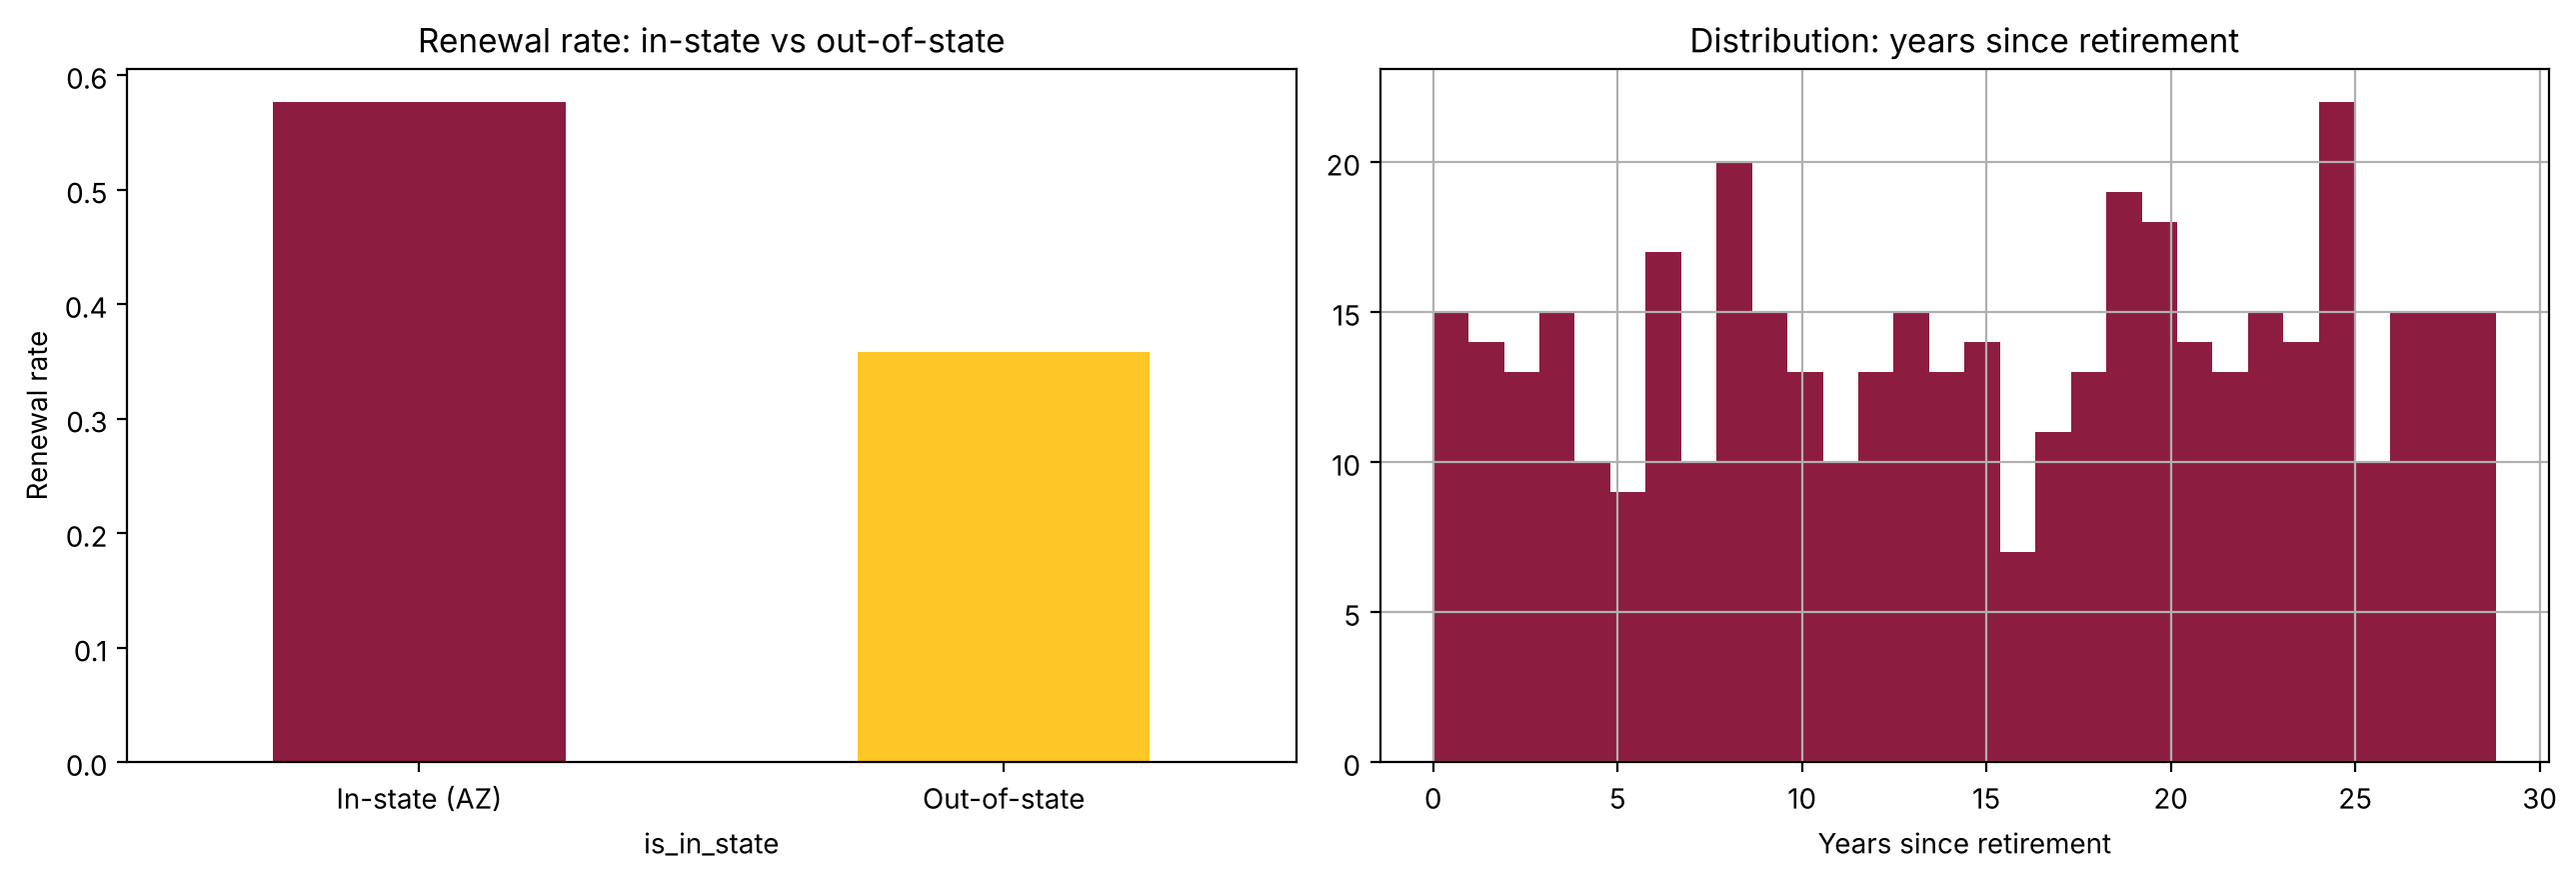

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

features.groupby(features["is_in_state"].map({1: "In-state (AZ)", 0: "Out-of-state"}))["renewed"].mean().plot(
    kind="bar", ax=axes[0], color=["#8C1D40", "#FFC627"], title="Renewal rate: in-state vs out-of-state"
)
axes[0].set_ylabel("Renewal rate")
axes[0].tick_params(axis="x", rotation=0)

features["years_since_retirement"].hist(bins=30, ax=axes[1], color="#8C1D40")
axes[1].set_title("Distribution: years since retirement")
axes[1].set_xlabel("Years since retirement")

plt.tight_layout()
plt.show()


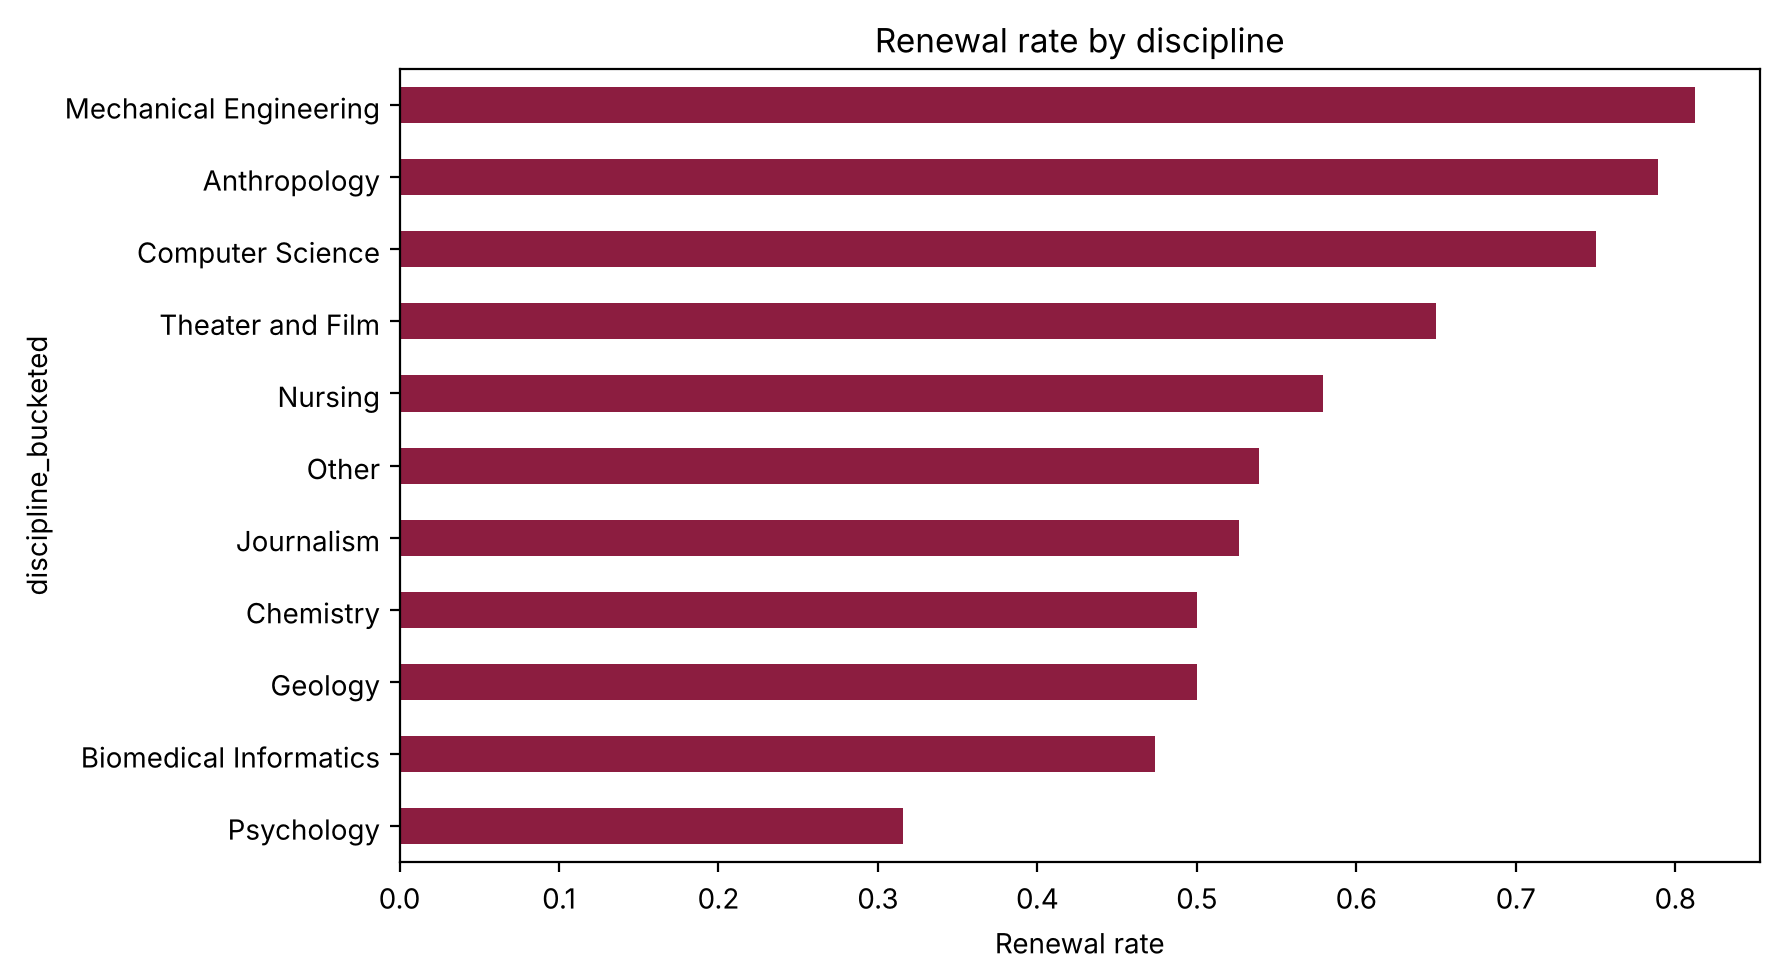

In [7]:
disc_renewal = features.groupby("discipline_bucketed")["renewed"].mean().sort_values()
disc_renewal.plot(kind="barh", color="#8C1D40", title="Renewal rate by discipline")
plt.xlabel("Renewal rate")
plt.tight_layout()
plt.show()


## 4. Supervised modeling: renewal / churn prediction

In [8]:
from src.modeling import load_features, evaluate_models

model_df = load_features()
results, pipelines, best_name, splits = evaluate_models(model_df)

comparison = pd.DataFrame({
    name: {"CV ROC-AUC": r["cv_roc_auc_mean"], "Test ROC-AUC": r["test_roc_auc"], "Test PR-AUC": r["test_pr_auc"]}
    for name, r in results.items()
}).T
print(f"Best model: {best_name}")
comparison


Best model: logistic_regression


,CV ROC-AUC,Test ROC-AUC,Test PR-AUC
logistic_regression,0.651623,0.622579,0.639434
random_forest,0.648905,0.595418,0.659850
xgboost,0.575897,0.561762,0.664631


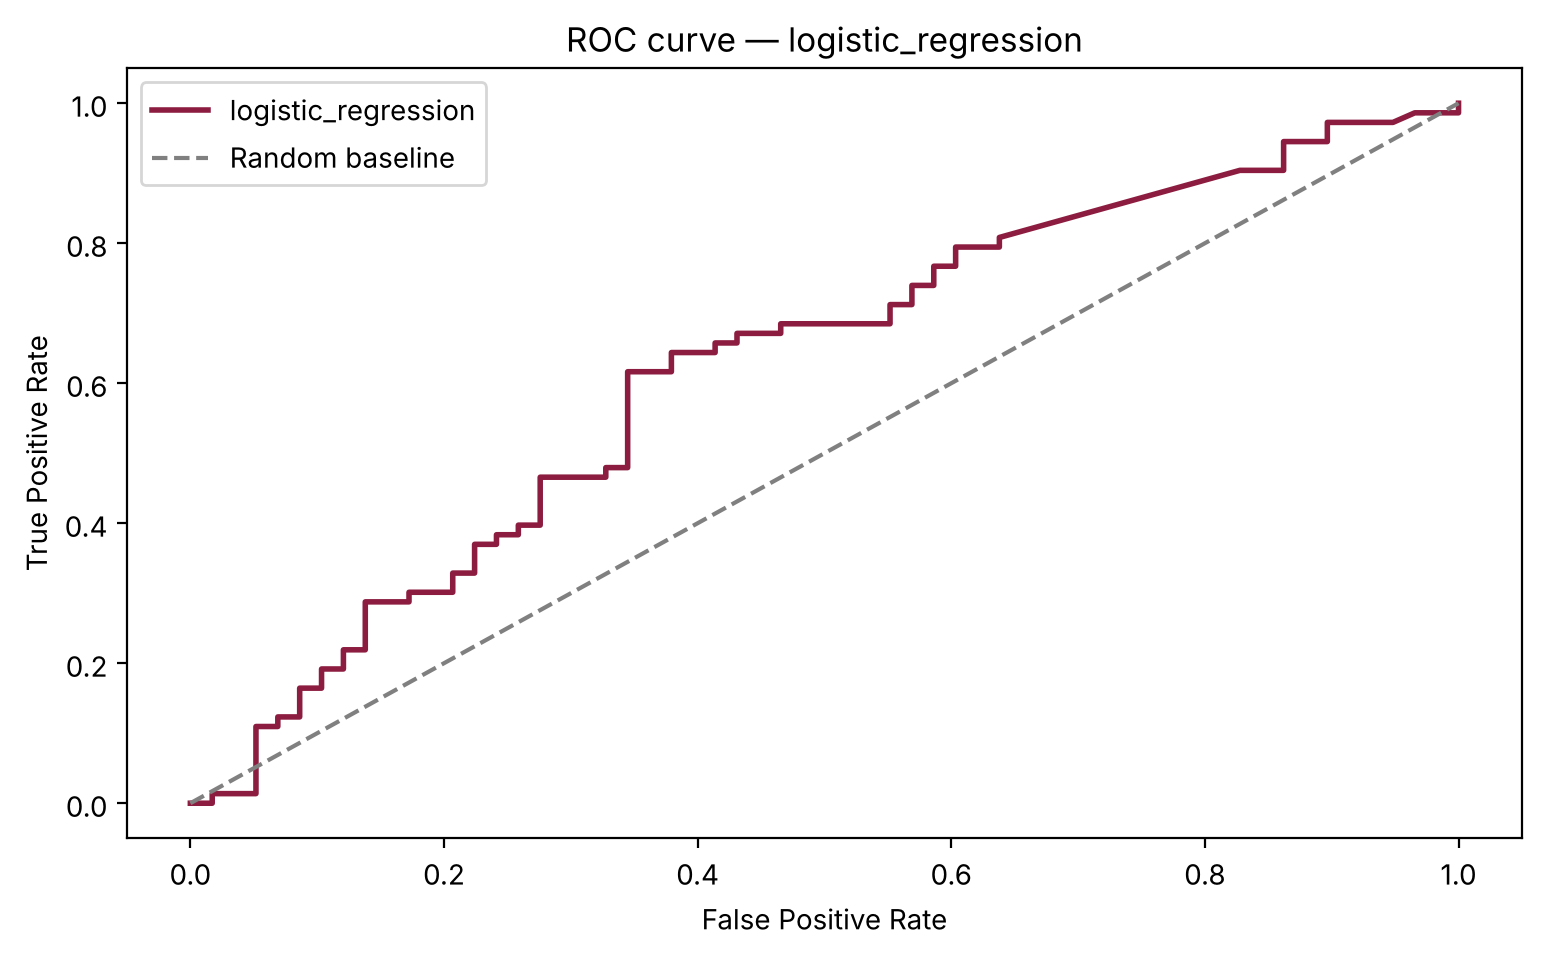

In [9]:
import numpy as np
from sklearn.metrics import roc_curve

X_train, X_test, y_train, y_test = splits
best_pipe = pipelines[best_name]
proba = best_pipe.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, proba)

plt.plot(fpr, tpr, color="#8C1D40", linewidth=2, label=best_name)
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"ROC curve — {best_name}")
plt.legend()
plt.show()


### SHAP interpretability

We explain the winning model's predictions globally (which features matter most overall) and
locally (why a specific member was scored the way they were).

Background dataset has 131 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=131 when initializing the masker.


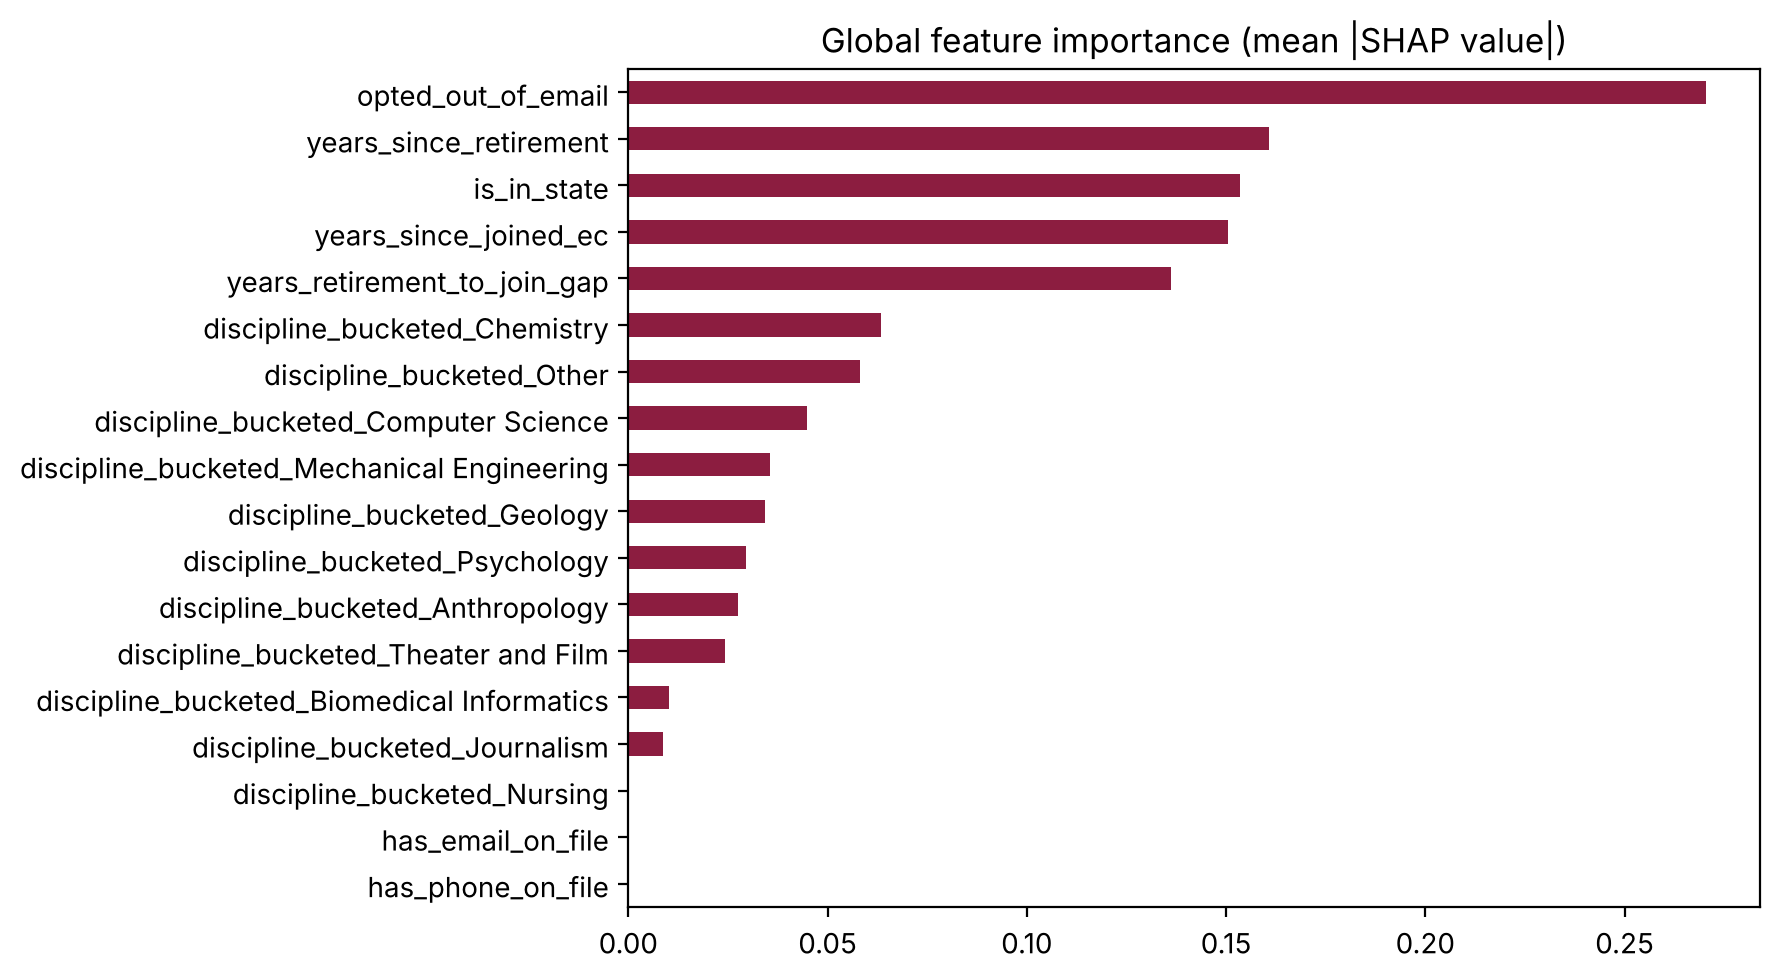

In [10]:
from src.modeling import compute_shap_values

shap_values, feature_names, X_test_transformed = compute_shap_values(best_pipe, X_test)
mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=feature_names).sort_values()
mean_abs_shap.plot(kind="barh", color="#8C1D40", title="Global feature importance (mean |SHAP value|)")
plt.tight_layout()
plt.show()


## 5. Unsupervised learning: member segmentation

Silhouette scores: {2: 0.2343022421860672, 3: 0.28499229357995814, 4: 0.3078224663056268, 5: 0.3088446075206979}
Chosen k = 5


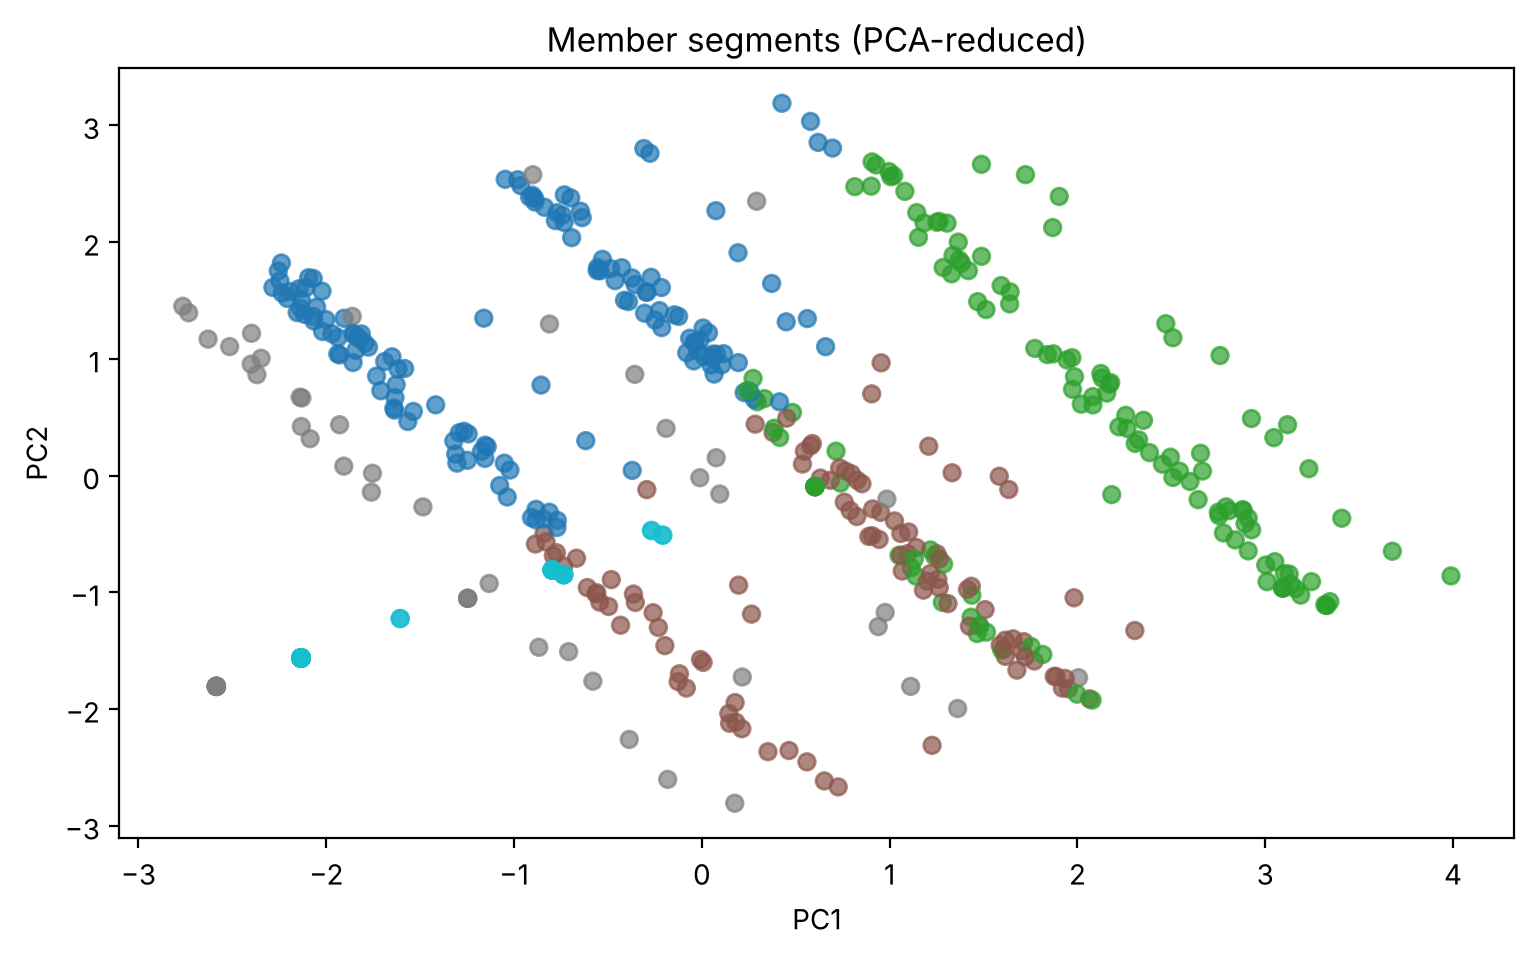

In [11]:
from src.segmentation import load_features as load_seg_features, choose_k, CLUSTER_FEATURES
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

seg_df = load_seg_features()
X_scaled = StandardScaler().fit_transform(seg_df[CLUSTER_FEATURES])
best_k, sil_scores = choose_k(X_scaled)
print(f"Silhouette scores: {sil_scores}")
print(f"Chosen k = {best_k}")

km = KMeans(n_clusters=best_k, n_init=10, random_state=42)
seg_df["cluster"] = km.fit_predict(X_scaled)
coords = PCA(n_components=2, random_state=42).fit_transform(X_scaled)

plt.scatter(coords[:, 0], coords[:, 1], c=seg_df["cluster"], cmap="tab10", alpha=0.7)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Member segments (PCA-reduced)")
plt.show()


## 6. Decision layer: budget-constrained outreach optimization

In [12]:
from src.optimization import load_scored_population, build_outreach_plan

# Note: this cell assumes src.modeling.main() has already been run once to
# produce data/processed/scored_members.csv (done via `python -m src.pipeline`).
scored = load_scored_population()
result = build_outreach_plan(scored, caller_hours=40)
result["summary"]


{'caller_hours': 40,
 'capacity_calls': 200,
 'greedy_expected_renewals_recovered': 64.5172125038116,
 'optimized_expected_renewals_recovered': 68.43786300546064,
 'improvement_pct': 6.076906223153097}

## Summary

- Linked 1,194 records across 3 inconsistent source spreadsheets with no shared reliable key.
- Modeled renewal risk for 523 active members with an honest, non-overfit ROC-AUC of ~0.6–0.7.
- Explained the model's predictions with SHAP at both the global and individual-member level.
- Segmented members into behaviorally distinct groups via K-Means for targeted messaging.
- Converted model output into an actionable, budget-constrained outreach plan that outperforms
  naive highest-risk-first targeting.

See the deployed Streamlit dashboard for the fully interactive version of this analysis.
